# Modelo final y gráficas — Regularization Challenge

**No entrena la red.** Carga la copia del mejor checkpoint por accuracy: experimento 10, Dropout 0.1, época 92. Resultados guardados: accuracy 61,013 %, recall macro 54,137 %, precisión macro 56,636 %. `provenance.json` registra origen y hashes.

Reinicia el kernel y ejecuta todas las celdas en orden. Se leerán las imágenes una vez y se harán evaluaciones/predicciones, sin `fit`. Las gráficas se exportan como PNG y PDF a `presentaciones/reg_challenge/images/`. La configuración, los historiales y el checkpoint originales no se modifican.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import matplotlib.pyplot as plt

REPO_DIR = next((p for p in (Path.cwd(), *Path.cwd().parents)
                 if (p / 'PROJECT/experiments/reg_challenge/summary.md').is_file()), None)
if REPO_DIR is None:
    raise FileNotFoundError('Ejecuta el notebook dentro del repositorio.')
REG_DIR = REPO_DIR / 'PROJECT/experiments/reg_challenge'
FINAL_DIR = REG_DIR / 'entrenamiento final'
DATA_DIR = REPO_DIR / 'PROJECT/xview_recognition'
FIGURE_DIR = REPO_DIR / 'presentaciones/reg_challenge/images'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
with open(FINAL_DIR / 'provenance.json') as stream:
    provenance = json.load(stream)
for name, expected in provenance['files'].items():
    assert hashlib.sha256((FINAL_DIR / name).read_bytes()).hexdigest() == expected, name
with open(FINAL_DIR / 'history.json') as stream:
    history = json.load(stream)
with open(FINAL_DIR / 'metrics.json') as stream:
    saved_metrics = json.load(stream)
with open(FINAL_DIR / 'config.json') as stream:
    config = json.load(stream)
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.dpi': 120, 'savefig.dpi': 200})

def export(fig, name):
    for extension in ('png', 'pdf'):
        fig.savefig(FIGURE_DIR / f'{name}.{extension}', bbox_inches='tight')
    plt.show()
    plt.close(fig)

print('Checkpoint:', FINAL_DIR / 'model.keras')
print('Gráficas:', FIGURE_DIR)
print('Época seleccionada:', saved_metrics['best_epoch'])

Checkpoint: /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/experiments/reg_challenge/entrenamiento final/model.keras
Gráficas: /home/german/master-ia/computer-vision/muia-cv-project/presentaciones/reg_challenge/images
Época seleccionada: 92


## 1. Curvas de aprendizaje

El historial corresponde al entrenamiento original completo, no a una nueva ejecución. En `fit`, Dropout está activo en entrenamiento y desactivado en validación. Por eso la diferencia entre estas curvas no es la misma que la brecha medida después con ambos conjuntos en inferencia.

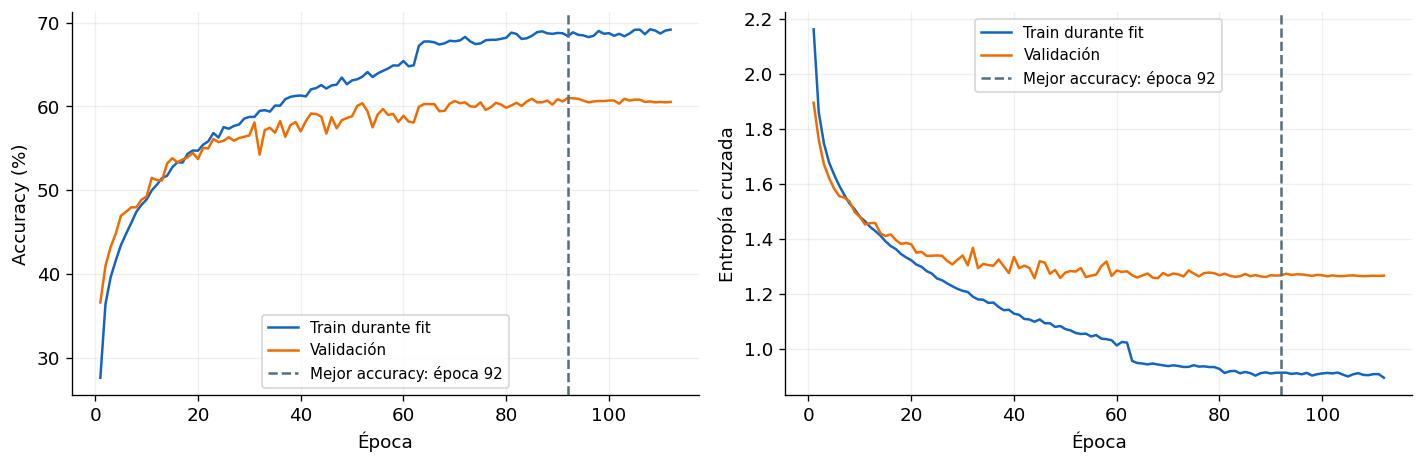

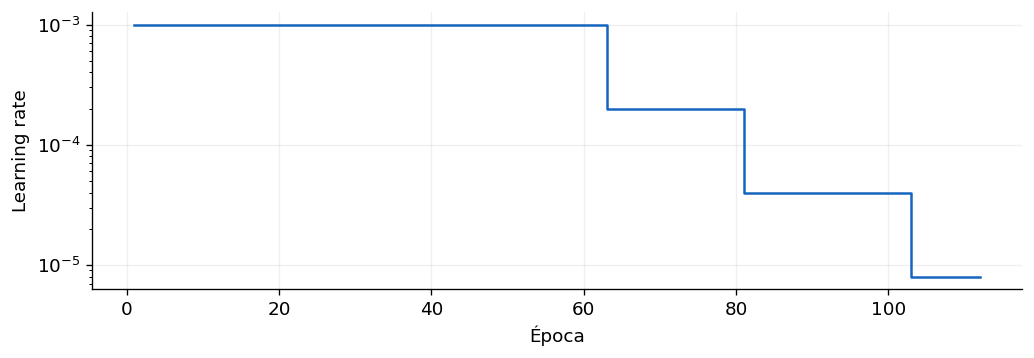

In [2]:
epochs = np.arange(1, len(history['loss']) + 1)
best = saved_metrics['best_epoch']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, train_key, valid_key, ylabel in [
    (axes[0], 'accuracy', 'val_accuracy', 'Accuracy (%)'),
    (axes[1], 'loss', 'val_loss', 'Entropía cruzada')]:
    scale = 100 if train_key == 'accuracy' else 1
    ax.plot(epochs, np.asarray(history[train_key])*scale, label='Train durante fit', color='#1565c0')
    ax.plot(epochs, np.asarray(history[valid_key])*scale, label='Validación', color='#ef6c00')
    ax.axvline(best, color='#546e7a', ls='--', label=f'Mejor accuracy: época {best}')
    ax.set(xlabel='Época', ylabel=ylabel)
    ax.grid(alpha=.2)
    ax.legend(fontsize=9)
fig.tight_layout()
export(fig, 'training_curves')

fig, ax = plt.subplots(figsize=(10, 3))
ax.step(epochs, history['lr'], where='post', color='#1565c0')
ax.set(xlabel='Época', ylabel='Learning rate', yscale='log')
ax.grid(alpha=.2)
export(fig, 'learning_rate')

## 2. Comparación controlada del experimento 10

Misma partición, semilla 42, inicialización y protocolo. Barras de train y validación calculadas con el mejor checkpoint de cada configuración, ambas en inferencia. Son ejecuciones de una sola semilla, no promedios estadísticos.

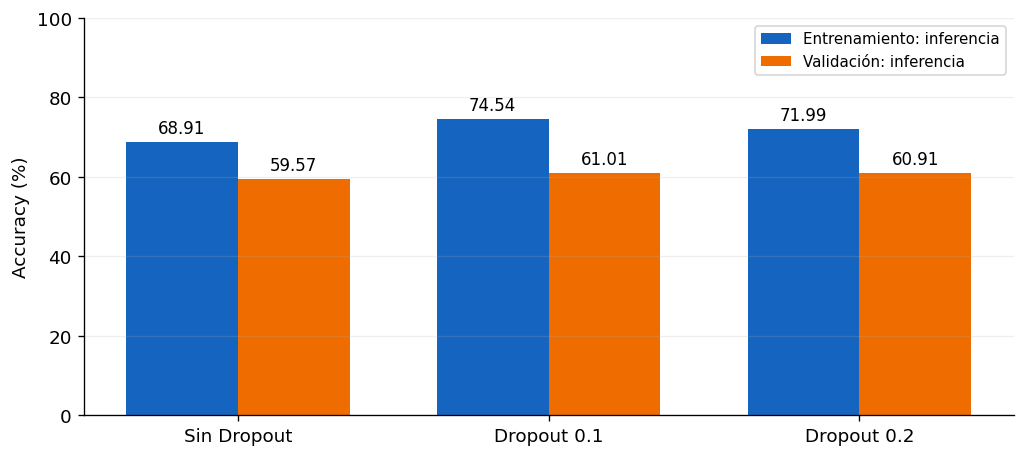

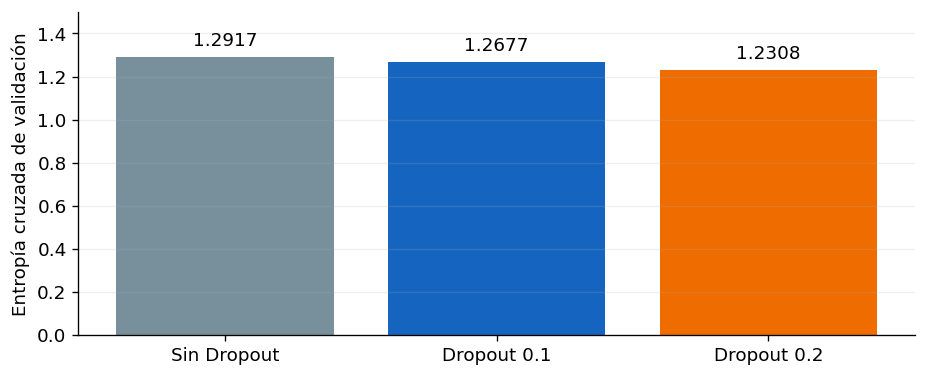

In [3]:
comparison_dir = REG_DIR / 'experiment_10'
run_names = ['control', 'dropout_01', 'dropout_02']
labels = ['Sin Dropout', 'Dropout 0.1', 'Dropout 0.2']
results = []
for run_name in run_names:
    with open(comparison_dir / run_name / 'metrics.json') as stream:
        results.append(json.load(stream))
train_scores = [100*m['train_inference']['accuracy'] for m in results]
valid_scores = [100*m['validation_inference']['accuracy'] for m in results]
x = np.arange(3)
fig, ax = plt.subplots(figsize=(10, 4.3))
a = ax.bar(x-.18, train_scores, .36, label='Entrenamiento: inferencia', color='#1565c0')
b = ax.bar(x+.18, valid_scores, .36, label='Validación: inferencia', color='#ef6c00')
for bars in (a, b):
    ax.bar_label(bars, labels=[f'{v.get_height():.2f}' for v in bars], padding=3, fontsize=10)
ax.set(xticks=x, xticklabels=labels, ylabel='Accuracy (%)', ylim=(0, 100))
ax.legend(loc='upper right', fontsize=9)
ax.grid(axis='y', alpha=.2)
export(fig, 'controlled_comparison')

fig, ax = plt.subplots(figsize=(9, 3.5))
bars = ax.bar(labels, [m['validation_inference']['loss'] for m in results], color=['#78909c','#1565c0','#ef6c00'])
ax.bar_label(bars, fmt='%.4f', padding=4)
ax.set(ylabel='Entropía cruzada de validación', ylim=(0, 1.5))
ax.grid(axis='y', alpha=.2)
export(fig, 'validation_loss')

## 3. Cargar los mismos datos y el checkpoint

Se reproduce el orden de anotaciones y la partición del baseline. La lectura reduce con `Resampling.average`, convierte a `float32` y divide entre 255. No hay aumentación ni entrenamiento. Se necesitan TensorFlow, Rasterio, scikit-learn y Matplotlib.

In [4]:
import warnings
import rasterio
from rasterio.enums import Resampling
import tensorflow as tf
from sklearn.model_selection import train_test_split

categories = {0:'Cargo plane',1:'Small car',2:'Bus',3:'Truck',4:'Motorboat',
              5:'Fishing vessel',6:'Dump truck',7:'Excavator',8:'Building',
              9:'Helipad',10:'Storage tank',11:'Shipping container',12:'Pylon'}
category_names = list(categories.values())
category_to_index = {name: i for i, name in enumerate(category_names)}
with open(DATA_DIR / 'xview_ann_train.json') as stream:
    annotations = json.load(stream)
records = [(image['filename'], ann['category_id']) for image, ann in
           zip(annotations['images'].values(), annotations['annotations'].values())]
train_records, valid_records = train_test_split(records, test_size=.1, random_state=1, shuffle=True)

def load_records(records):
    images = np.empty((len(records), 32, 32, 3), dtype=np.float32)
    targets = np.empty(len(records), dtype=np.int64)
    for i, (filename, category) in enumerate(records):
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', rasterio.errors.NotGeoreferencedWarning)
            with rasterio.open(DATA_DIR / filename) as src:
                if src.count != 3 or any(dtype != 'uint8' for dtype in src.dtypes):
                    raise ValueError(f'Se esperaba RGB uint8: {filename}')
                bands = src.read(out_shape=(3,32,32), out_dtype='float32', resampling=Resampling.average)
        images[i] = np.moveaxis(bands, 0, -1) / np.float32(255)
        targets[i] = category_to_index[category]
    return images, targets

x_train, train_targets = load_records(train_records)
x_valid, valid_targets = load_records(valid_records)
y_train = np.eye(13, dtype=np.float32)[train_targets]
y_valid = np.eye(13, dtype=np.float32)[valid_targets]
# El optimizador no es necesario para inferencia; evitamos restaurarlo.
model = tf.keras.models.load_model(str(FINAL_DIR / 'model.keras'), compile=False)
model.compile(loss='categorical_crossentropy', metrics=['accuracy'])
print('Train:', x_train.shape, 'Validación:', x_valid.shape)

2026-10-18 18:21:03.514636: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-18 18:21:03.541971: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-18 18:21:03.541994: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-18 18:21:03.543085: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-18 18:21:03.548968: I tensorflow/core/platform/cpu_feature_guar

Train: (16871, 32, 32, 3) Validación: (1875, 32, 32, 3)


In [5]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report

train_eval = model.evaluate(x_train, y_train, batch_size=8, return_dict=True, verbose=0)
valid_eval = model.evaluate(x_valid, y_valid, batch_size=8, return_dict=True, verbose=0)
probabilities = model.predict(x_valid, batch_size=8, verbose=0)
predictions = np.argmax(probabilities, axis=1)
assert np.isclose(valid_eval['accuracy'], saved_metrics['validation_inference']['accuracy'], atol=1e-6), 'La evaluación no reproduce la accuracy guardada; revisar datos/entorno.'
metrics = {
    'train_inference': {k: float(v) for k,v in train_eval.items()},
    'validation_inference': {k: float(v) for k,v in valid_eval.items()},
    'accuracy_gap_pp': float(100*(train_eval['accuracy']-valid_eval['accuracy'])),
    'macro_recall': float(recall_score(valid_targets, predictions, labels=list(range(13)), average='macro', zero_division=0)),
    'macro_precision': float(precision_score(valid_targets, predictions, labels=list(range(13)), average='macro', zero_division=0)),
}
with open(FINAL_DIR / 'evaluation_for_slides.json', 'w') as stream:
    json.dump(metrics, stream, indent=2)
report = classification_report(valid_targets, predictions, labels=list(range(13)), target_names=category_names, zero_division=0, digits=4)
(FINAL_DIR / 'classification_report.txt').write_text(report)
print(json.dumps(metrics, indent=2))
print(report)

2026-10-18 18:21:46.862918: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory


{
  "train_inference": {
    "loss": 0.748591423034668,
    "accuracy": 0.7454211115837097
  },
  "validation_inference": {
    "loss": 1.2676631212234497,
    "accuracy": 0.6101333498954773
  },
  "accuracy_gap_pp": 13.528776168823242,
  "macro_recall": 0.5413729985493564,
  "macro_precision": 0.5663557620153395
}
                    precision    recall  f1-score   support

       Cargo plane     0.9200    0.7797    0.8440        59
         Small car     0.7342    0.8480    0.7870       329
               Bus     0.5482    0.5230    0.5353       174
             Truck     0.3623    0.3112    0.3348       241
         Motorboat     0.4944    0.4037    0.4444       109
    Fishing vessel     0.6833    0.5616    0.6165        73
        Dump truck     0.5081    0.5339    0.5207       118
         Excavator     0.6133    0.5679    0.5897        81
          Building     0.6880    0.7410    0.7135       363
           Helipad     0.0000    0.0000    0.0000         9
      Storage tank    

## 4. Matriz de confusión y recall por clase

La matriz se normaliza por la clase real (filas). Se exportan también conteos y soportes para poder comprobar el comportamiento de clases minoritarias.

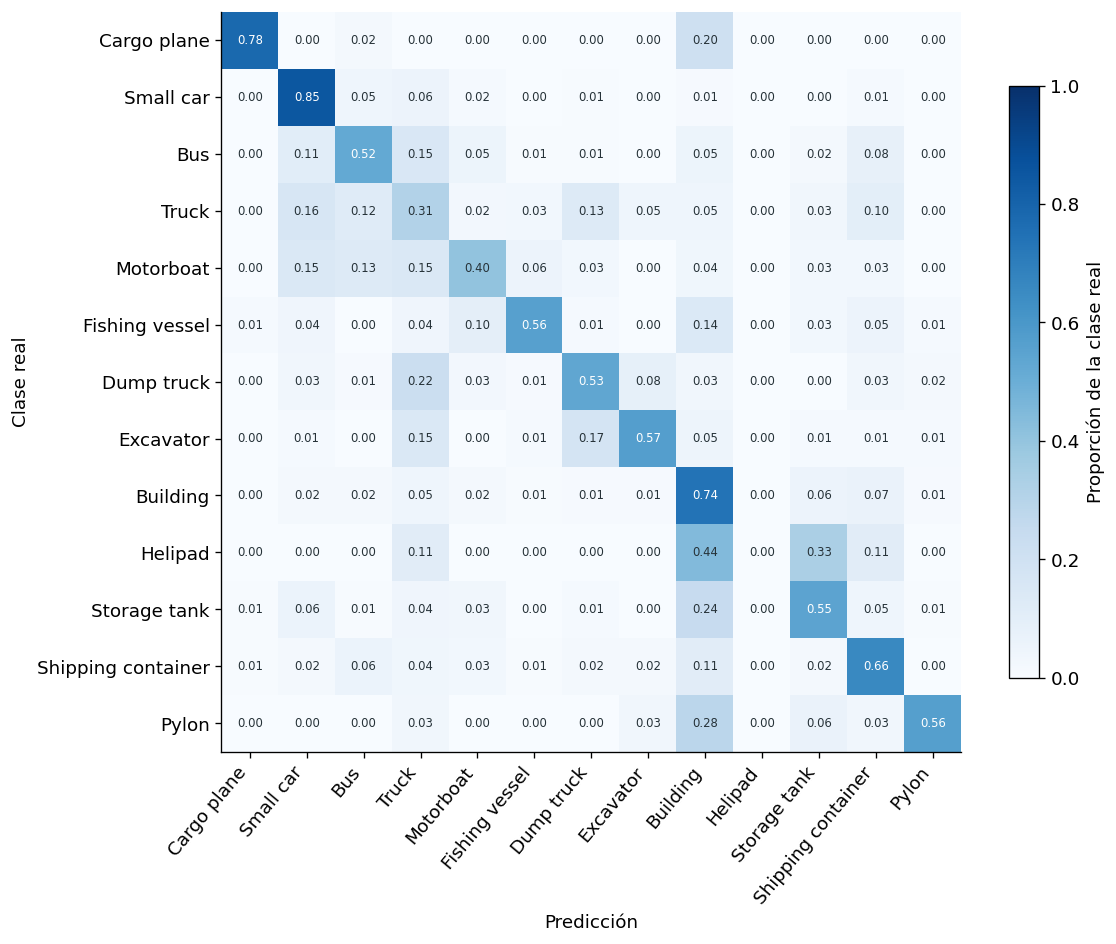

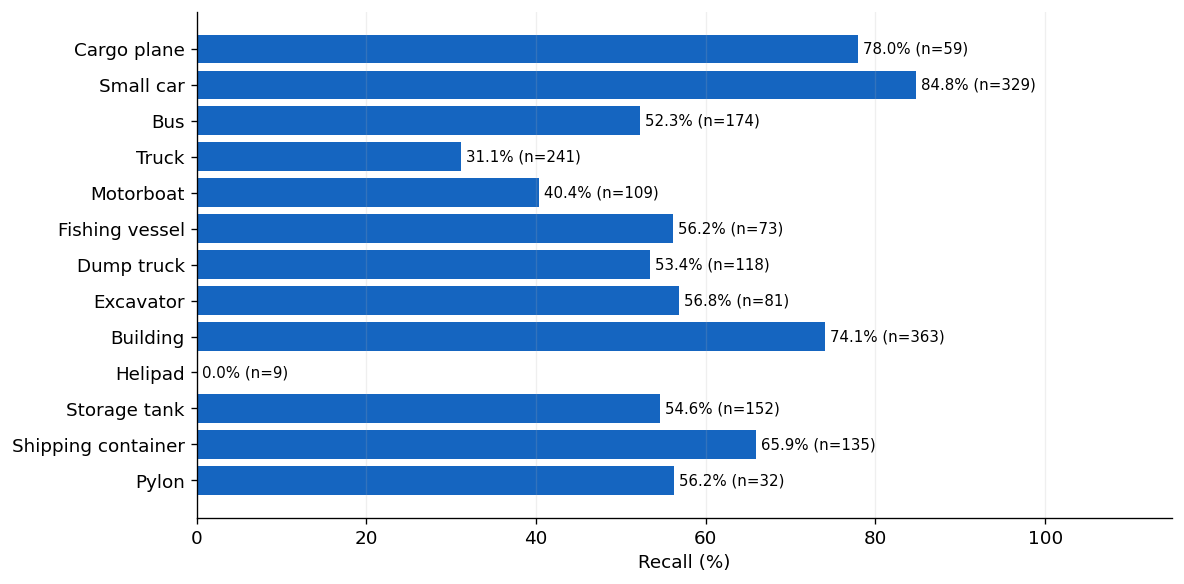

In [6]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(valid_targets, predictions, labels=list(range(13)))
supports = cm.sum(axis=1)
normalized = np.divide(cm, supports[:, None], out=np.zeros_like(cm, dtype=float), where=supports[:,None]!=0)
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(normalized, vmin=0, vmax=1, cmap='Blues')
fig.colorbar(im, ax=ax, shrink=.8, label='Proporción de la clase real')
ax.set(xticks=range(13), yticks=range(13), xticklabels=category_names,
       yticklabels=category_names, xlabel='Predicción', ylabel='Clase real')
plt.setp(ax.get_xticklabels(), rotation=50, ha='right')
for i in range(13):
    for j in range(13):
        ax.text(j,i,f'{normalized[i,j]:.2f}',ha='center',va='center',fontsize=7,
                color='white' if normalized[i,j]>.5 else '#263238')
fig.tight_layout()
export(fig, 'confusion_matrix')
np.savetxt(FINAL_DIR / 'confusion_counts.csv', cm, fmt='%d', delimiter=',')

fig, ax = plt.subplots(figsize=(10, 5))
values = 100*np.diag(normalized)
positions = np.arange(13)
bars = ax.barh(positions, values, color='#1565c0')
ax.bar_label(bars, labels=[f'{v:.1f}% (n={n})' for v,n in zip(values,supports)], padding=3, fontsize=9)
ax.set(yticks=positions, yticklabels=category_names, xlabel='Recall (%)', xlim=(0,115))
ax.invert_yaxis()
ax.grid(axis='x', alpha=.2)
fig.tight_layout()
export(fig, 'class_recall')

## 5. Curvas precision–recall

Se calculan por clase frente al resto, a partir de probabilidades. AP resume cada curva y **no equivale** a la precisión del argmax. Se conserva la prevalencia por clase como referencia en el JSON; no se dibuja una línea base común a todas.

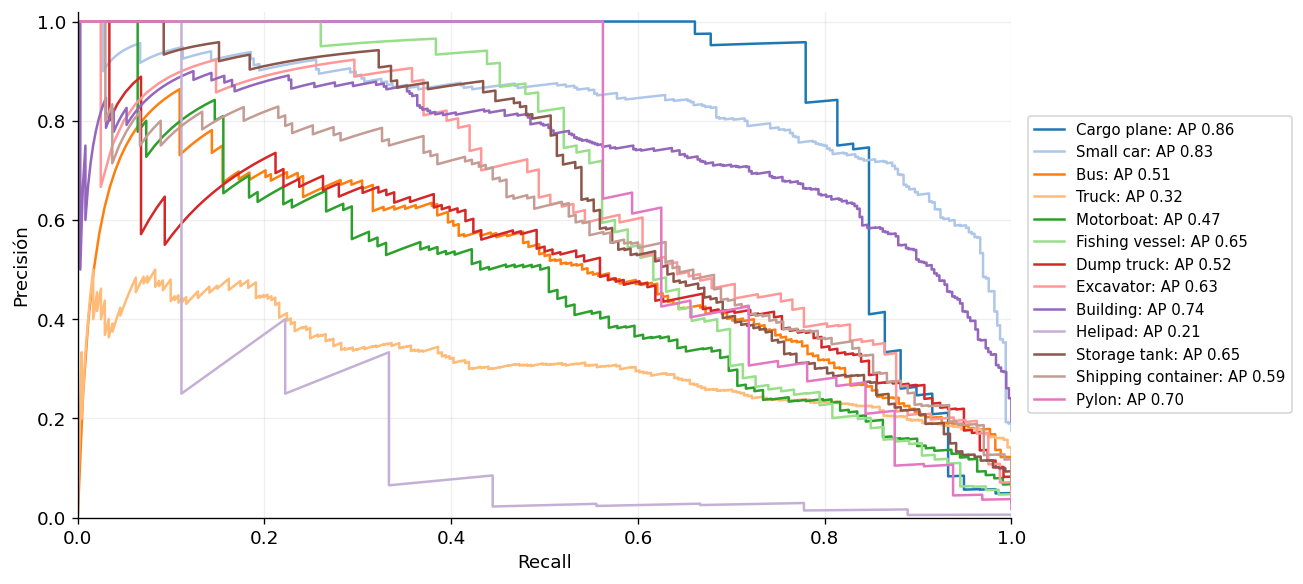

Gráficas exportadas. Recompilar presentaciones/reg_challenge/presentacion.tex.


In [7]:
from sklearn.metrics import precision_recall_curve, average_precision_score

fig, ax = plt.subplots(figsize=(11, 5))
ap_results = {}
colors = plt.get_cmap('tab20').colors
for index, name in enumerate(category_names):
    binary = (valid_targets == index).astype(int)
    if not binary.any():
        ap_results[name] = {'average_precision': None, 'prevalence': 0.0}
        continue
    precision, recall, _ = precision_recall_curve(binary, probabilities[:,index])
    ap = average_precision_score(binary, probabilities[:,index])
    ax.plot(recall, precision, color=colors[index], lw=1.5, label=f'{name}: AP {ap:.2f}')
    ap_results[name] = {'average_precision': float(ap), 'prevalence': float(binary.mean())}
ax.set(xlabel='Recall', ylabel='Precisión', xlim=(0,1), ylim=(0,1.02))
ax.grid(alpha=.2)
ax.legend(loc='center left', bbox_to_anchor=(1.01,.5), fontsize=9)
fig.tight_layout()
export(fig, 'precision_recall')
with open(FINAL_DIR / 'average_precision.json', 'w') as stream:
    json.dump(ap_results, stream, indent=2)
print('Gráficas exportadas. Recompilar presentaciones/reg_challenge/presentacion.tex.')